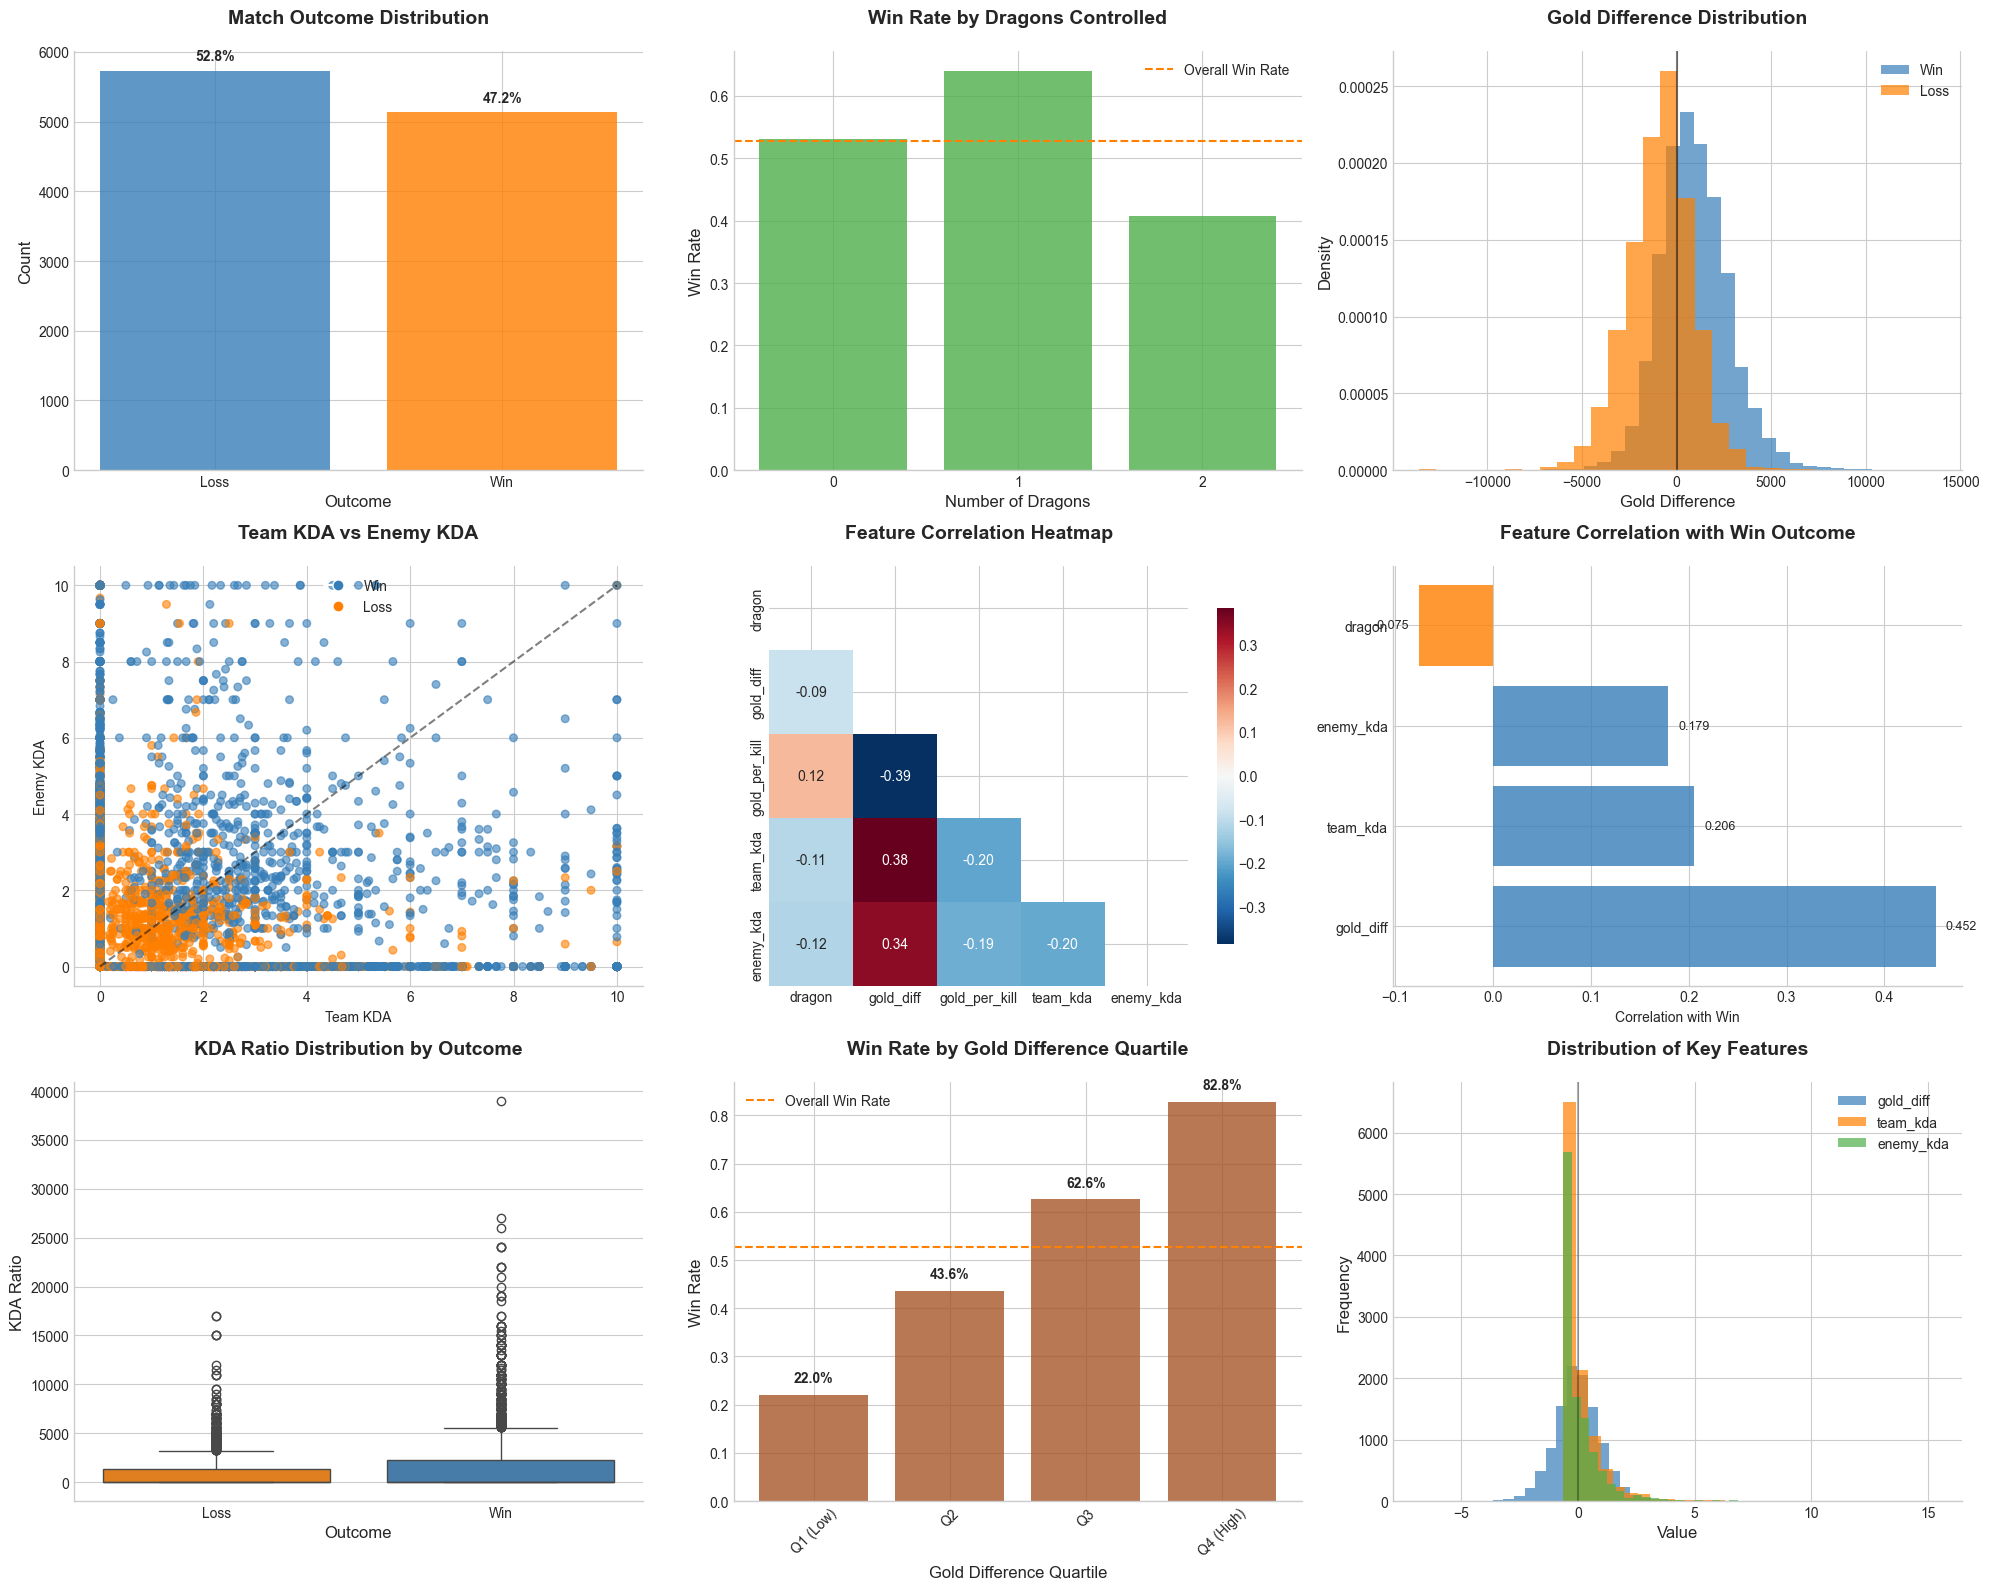

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import colors
import warnings
warnings.filterwarnings('ignore')

# Set up colorblind-friendly palette and style
CB_COLORS = ['#377eb8', '#ff7f00', '#4daf4a', '#f781bf', '#a65628', 
            '#984ea3', '#999999', '#e41a1c', '#dede00']

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette(CB_COLORS)

# Create a function for consistent styling
def apply_style(ax, title, xlabel=None, ylabel=None, legend_title=None):
    """Apply consistent styling to plots"""
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=12)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=12)
    if legend_title and ax.get_legend():
        ax.get_legend().set_title(legend_title)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Load and preprocess the data
df = pd.read_csv("League_of_Legends_data.csv")

def preprocess_lol_data(df):
    df_clean = df.copy()

    # Calculate team KDA (players 1-5)
    team_kills = 0
    team_deaths = 0
    team_assists = 0

    for i in range(1, 6):
        team_kills += df_clean[f'player_{i}_kills']
        team_deaths += df_clean[f'player_{i}_deaths']
        team_assists += df_clean[f'player_{i}_assists']

    # Calculate enemy KDA (players 6-10)
    enemy_kills = 0
    enemy_deaths = 0
    enemy_assists = 0

    for i in range(6, 11):
        enemy_kills += df_clean[f'player_{i}_kills']
        enemy_deaths += df_clean[f'player_{i}_deaths']
        enemy_assists += df_clean[f'player_{i}_assists']

    # KDA = (kills + assists) / max(1, deaths)
    df_clean['team_kda'] = (team_kills + team_assists) / team_deaths.clip(lower=1)
    df_clean['enemy_kda'] = (enemy_kills + enemy_assists) / enemy_deaths.clip(lower=1)

    # Gold difference
    df_clean['gold_diff'] = df_clean['team_gold'] - df_clean['enemy_gold']

    # Drop all individual player columns and redundant totals
    player_columns = []
    for i in range(1, 11):
        player_columns.extend([f'player_{i}_kills', f'player_{i}_deaths', f'player_{i}_assists'])

    redundant_columns = player_columns + ['total_kills', 'total_deaths', 'total_assists', 'kda_ratio', 'team_gold', 'enemy_gold']
    df_clean = df_clean.drop(columns=redundant_columns, errors='ignore')

    return df_clean

df_clean = preprocess_lol_data(df)

# Create EDA visualizations
fig = plt.figure(figsize=(20, 16))

# Target Distribution
plt.subplot(3, 3, 1)
win_counts = df_clean['win'].value_counts()
colors_win = [CB_COLORS[0] if val else CB_COLORS[1] for val in win_counts.index]
bars = plt.bar(['Loss', 'Win'], win_counts.values, color=colors_win, alpha=0.8)
plt.ylabel('Number of Matches')
apply_style(plt.gca(), 'Match Outcome Distribution', 'Outcome', 'Count')

# Add percentage labels
total = sum(win_counts.values)
for i, bar in enumerate(bars):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + total*0.01,
             f'{height/total:.1%}', ha='center', va='bottom', fontweight='bold')

# Dragon Control vs Win Rate
plt.subplot(3, 3, 2)
dragon_win_rate = df_clean.groupby('dragon')['win'].mean()
plt.bar(dragon_win_rate.index.astype(str), dragon_win_rate.values, 
        color=CB_COLORS[2], alpha=0.8)
plt.axhline(y=df_clean['win'].mean(), color=CB_COLORS[1], linestyle='--', 
            label='Overall Win Rate')
plt.legend()
apply_style(plt.gca(), 'Win Rate by Dragons Controlled', 'Number of Dragons', 'Win Rate')

# Gold Difference Distribution by Outcome
plt.subplot(3, 3, 3)
for outcome, color in zip([True, False], [CB_COLORS[0], CB_COLORS[1]]):
    subset = df_clean[df_clean['win'] == outcome]
    plt.hist(subset['gold_diff'], bins=30, alpha=0.7, 
             label='Win' if outcome else 'Loss', color=color, density=True)
plt.axvline(x=0, color='black', linestyle='-', alpha=0.5)
plt.legend()
apply_style(plt.gca(), 'Gold Difference Distribution', 'Gold Difference', 'Density')

# Team KDA vs Enemy KDA
plt.subplot(3, 3, 4)
# Cap KDA for better visualization
kda_cap = 10
team_kda_capped = df_clean['team_kda'].clip(upper=kda_cap)
enemy_kda_capped = df_clean['enemy_kda'].clip(upper=kda_cap)

plt.scatter(team_kda_capped, enemy_kda_capped, 
           c=df_clean['win'].map({True: CB_COLORS[0], False: CB_COLORS[1]}), 
           alpha=0.6, s=30)
plt.plot([0, kda_cap], [0, kda_cap], 'k--', alpha=0.5)
plt.xlabel('Team KDA')
plt.ylabel('Enemy KDA')
apply_style(plt.gca(), 'Team KDA vs Enemy KDA')

# Create custom legend for scatter plot
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor=CB_COLORS[0], 
                      markersize=8, label='Win'),
                  Line2D([0], [0], marker='o', color='w', markerfacecolor=CB_COLORS[1], 
                      markersize=8, label='Loss')]
plt.legend(handles=legend_elements)

# Correlation Heatmap
plt.subplot(3, 3, 5)
# Select only numeric columns for correlation
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
correlation_matrix = df_clean[numeric_cols].corr()

# Create mask for upper triangle
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.2f', 
           cmap='RdBu_r', center=0, square=True, 
           cbar_kws={'shrink': 0.8})
apply_style(plt.gca(), 'Feature Correlation Heatmap')

# Feature Correlation with Win
plt.subplot(3, 3, 6)
# Calculate correlation of each feature with win as numeric
win_correlations = {}
for col in ['gold_diff', 'team_kda', 'enemy_kda', 'dragon']:
    if col in df_clean.columns:
        win_correlations[col] = df_clean[col].corr(df_clean['win'].astype(int))

# Sort by absolute correlation
win_corr_series = pd.Series(win_correlations)
win_corr_sorted = win_corr_series.sort_values(key=abs, ascending=False)

colors_feat = [CB_COLORS[0] if x > 0 else CB_COLORS[1] for x in win_corr_sorted.values]
y_pos = np.arange(len(win_corr_sorted))

plt.barh(y_pos, win_corr_sorted.values, color=colors_feat, alpha=0.8)
plt.yticks(y_pos, win_corr_sorted.index)
plt.xlabel('Correlation with Win')
apply_style(plt.gca(), 'Feature Correlation with Win Outcome')

# Add value labels
for i, v in enumerate(win_corr_sorted.values):
    plt.text(v + (0.01 if v > 0 else -0.01), i, f'{v:.3f}', 
             ha='left' if v > 0 else 'right', va='center', fontsize=9)

# KDA Ratio Distribution by Outcome
plt.subplot(3, 3, 7)
df_clean['kda_ratio'] = df_clean['team_kda'] / (df_clean['enemy_kda'] + 0.001)

sns.boxplot(x='win', y='kda_ratio', data=df_clean, 
            palette=[CB_COLORS[1], CB_COLORS[0]])
plt.xticks([0, 1], ['Loss', 'Win'])
plt.ylabel('Team KDA / Enemy KDA Ratio')
apply_style(plt.gca(), 'KDA Ratio Distribution by Outcome', 'Outcome', 'KDA Ratio')

# Win Rate by Gold Difference Quartiles
plt.subplot(3, 3, 8)
df_clean['gold_diff_quartile'] = pd.qcut(df_clean['gold_diff'], 4, 
                                       labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
quartile_win_rate = df_clean.groupby('gold_diff_quartile')['win'].mean().sort_index()

plt.bar(quartile_win_rate.index.astype(str), quartile_win_rate.values, 
        color=CB_COLORS[4], alpha=0.8)
plt.axhline(y=df_clean['win'].mean(), color=CB_COLORS[1], linestyle='--', 
            label='Overall Win Rate')
plt.legend()
plt.xticks(rotation=45)
apply_style(plt.gca(), 'Win Rate by Gold Difference Quartile', 'Gold Difference Quartile', 'Win Rate')

# Add percentage labels
for i, v in enumerate(quartile_win_rate.values):
    plt.text(i, v + 0.02, f'{v:.1%}', ha='center', va='bottom', fontweight='bold')

# Feature Distributions
plt.subplot(3, 3, 9)
key_features = ['gold_diff', 'team_kda', 'enemy_kda']

for i, feature in enumerate(key_features):
    data = df_clean[feature]
    
    # Standardize the data
    data_standardized = (data - data.mean()) / data.std()
    
    plt.hist(data_standardized, bins=30, alpha=0.7, label=feature, 
             color=CB_COLORS[i], density=False)

plt.axvline(x=0, color='black', linestyle='-', alpha=0.3)
plt.legend()
apply_style(plt.gca(), 'Distribution of Key Features', 'Value', 'Frequency')

plt.tight_layout()
plt.show()